# 01 測量品質：幸福指數、家庭導向、重要性題組可靠嗎？

在比較「工作」與「家庭」誰對幸福比較重要之前，要先確認三件事：
1. **幸福指數**是否真的量到同一件事（信度、因素結構），而且不會因為網路自填或面訪而變形；
2. **家庭導向（FO）**與**家庭價值重要性**題組的結構與信度；
3. 這些「態度」是不是穩定的個人特質（跨年相關），否則拿它來當個人權重本身就不成立。

判斷標準：Cronbach's α ≥ 0.70 為可接受（Nunnally, 1978），0.60–0.70 為研究用尚可；態度題的跨年再測相關 0.5–0.7 屬於中度穩定的特質。

In [1]:
import numpy as np, pandas as pd
from sklearn.decomposition import FactorAnalysis
from psfd_utils import *
plt = setup_plot()
main = pd.read_csv(DERIVED / "main_2020_2024.csv", low_memory=False)
att = pd.read_csv(DERIVED / "attitudes_long.csv", low_memory=False)
AFF = [f"aff_{i}" for i in range(6)]
AFF_NAME = ["安心", "穩重沈著", "知足", "不緊張不安", "困難不會一直增加", "不過度擔心"]


def efa(X, k, names=None):
    Xs = (X - X.mean()) / X.std()
    fa = FactorAnalysis(k, rotation="varimax" if k > 1 else None, random_state=0).fit(Xs)
    L = pd.DataFrame(fa.components_.T, index=names or X.columns, columns=[f"F{i+1}" for i in range(k)])
    return L.round(2)

## 1. 幸福指數：三個面向是同一件事嗎？

In [2]:
rows = []
for y in [2020, 2022, 2024]:
    s = main[main.year == y]
    items8 = pd.concat([s.happy, s.good, s[AFF]], axis=1).dropna()
    ev = np.linalg.eigvalsh(np.corrcoef(((items8 - items8.mean()) / items8.std()).T))[::-1]
    rows.append(dict(year=y, N=len(items8), alpha_8題=cronbach_alpha(items8),
                     alpha_情緒6題=cronbach_alpha(s[AFF]),
                     第一特徵值=ev[0], 第二特徵值=ev[1], 第一因素解釋變異=ev[0] / len(ev),
                     r_快樂_生活評價=s.happy.corr(s.good), r_快樂_情緒=s.happy.corr(s.affect6),
                     r_生活評價_情緒=s.good.corr(s.affect6)))
pd.DataFrame(rows).round(3)

,year,N,alpha_8題,alpha_情緒6題,第一特徵值,第二特徵值,第一因素解釋變異,r_快樂_生活評價,r_快樂_情緒,r_生活評價_情緒
0,2020,5448,0.784,0.758,3.342,1.201,0.418,0.741,0.418,0.410
1,2022,5496,0.813,0.804,3.693,1.139,0.462,0.732,0.464,0.436
2,2024,5205,0.819,0.801,3.703,1.146,0.463,0.743,0.467,0.441


8 題的 α 在 0.78–0.82，且第一個特徵值明顯大於第二個——三個面向可以合成一個指數。
快樂與生活評價高度相關（r≈0.7），情緒與兩者中度相關（r≈0.5），這符合 Diener 的主觀幸福三元論：
認知評價與情緒相關但不相同，所以要兩者都量。

In [3]:
s = main[main.year == 2022]
L = efa(pd.concat([s.happy, s.good, s[AFF]], axis=1).dropna(), 2, ["快樂", "生活評價"] + AFF_NAME)
L

,F1,F2
快樂,-0.83,-0.20
生活評價,-0.83,-0.16
安心,-0.32,-0.63
穩重沈著,-0.16,-0.56
知足,-0.27,-0.51
不緊張不安,-0.29,-0.62
困難不會一直增加,-0.34,-0.60
不過度擔心,-0.17,-0.58


兩因素解：快樂、生活評價一個因素，情緒題一個因素——與「生活評價 vs 情緒」的理論區分一致，所以我們用「三面向等權」而不是 8 題直接平均（直接平均會讓情緒 6 題佔 75% 權重）。

### 1.1 網路自填 vs 面訪：分數有系統性差異嗎？

PSFD 自 2018 起部分樣本改網路自填；Tu & Yu (2026) 指出主觀幸福題有模式效應。我們比較兩種模式的平均數，並在後續所有模型控制 `web`。

In [4]:
rows = []
for y in [2020, 2022, 2024]:
    s = main[main.year == y]
    for w, g in s.groupby("web"):
        rows.append(dict(year=y, 模式="網路自填" if w == 1 else "面訪", N=len(g), 快樂=g.happy.mean(),
                         生活評價=g.good.mean(), 情緒=g.affect6.mean(), 幸福分數=g.swb.mean(), 年齡=g.age.mean(),
                         alpha=cronbach_alpha(pd.concat([g.happy, g.good, g[AFF]], axis=1))))
mode_tab = pd.DataFrame(rows).round(2)
mode_tab

,year,模式,N,快樂,生活評價,情緒,幸福分數,年齡,alpha
0,2020,面訪,3248,4.93,4.91,3.02,66.09,47.84,0.78
1,2020,網路自填,2551,4.91,5.01,2.90,65.29,37.97,0.79
2,2022,面訪,4355,4.90,4.86,2.98,65.19,45.94,0.81
3,2022,網路自填,1290,4.89,4.89,2.92,64.91,40.07,0.83
4,2024,面訪,4250,5.01,4.99,3.02,66.98,47.17,0.82
5,2024,網路自填,1162,5.11,5.16,2.94,67.48,41.44,0.83


In [5]:
import statsmodels.formula.api as smf
for comp in ["swb", "happy", "good", "affect6"]:
    d = main.dropna(subset=[comp, "web", "age", "female"])
    m = smf.ols(f"{comp} ~ web + age + I(age**2) + female + C(year)", d).fit(cov_type="cluster", cov_kwds={"groups": d.pid})
    print(f"{comp:8s} 網路自填 vs 面訪（控制年齡、性別、年份）：差 {m.params['web']:+.3f}（p = {m.pvalues['web']:.4f}）")

swb      網路自填 vs 面訪（控制年齡、性別、年份）：差 +0.531（p = 0.2000）
happy    網路自填 vs 面訪（控制年齡、性別、年份）：差 +0.006（p = 0.8429）
good     網路自填 vs 面訪（控制年齡、性別、年份）：差 +0.103（p = 0.0007）


affect6  網路自填 vs 面訪（控制年齡、性別、年份）：差 -0.019（p = 0.1154）


網路自填者比較年輕（平均小 6–10 歲）。控制年齡、性別、年份後，整體幸福分數在兩種模式間沒有顯著差異；拆開來看，只有「生活過得好不好」網路自填者略高 0.10 分（7 分量表，p<0.001），快樂與情緒沒有差異。
這與 Tu & Yu (2026) 用 PSFD 發現的「混合模式效應因題目與受訪者特性而異」一致。兩種模式的 α 相近（結構沒有變形），所以後續模型一律控制 `web` 即可，不需要分開分析。

### 1.2 三面向指數 vs 兩題版：長資料（2007–2024）只能用兩題版，兩者差多少？

In [6]:
for y in [2020, 2022, 2024]:
    s = main[main.year == y]
    print(y, "swb 與 swb2 的相關 r =", round(s.swb.corr(s.swb2), 3))

2020 swb 與 swb2 的相關 r = 0.954
2022 swb 與 swb2 的相關 r = 0.956
2024 swb 與 swb2 的相關 r = 0.95


r≈0.94，兩題版可以代表三面向指數，因此 18 年長資料用兩題版是合理的近似。

## 2. 家庭導向（FO）：結構、信度、穩定度

In [7]:
MAR = ["mar_a", "mar_b", "mar_c", "mar_d", "mar_f", "mar_g"]
GEN = ["gen_a", "gen_b", "gen_c", "gen_d", "gen_e", "gen_f", "gen_g", "gen_h"]
NAMES = {"mar_a": "婚後一定要有小孩", "mar_b": "不贊成不婚同居", "mar_c": "不好的婚姻也比單身好",
         "mar_d": "不贊成非婚生子", "mar_f": "結婚比離婚快樂", "mar_g": "結婚比不婚快樂",
         "gen_a": "職業婦女≠好媽媽", "gen_b": "母親工作對幼兒不好", "gen_c": "妻子全職對家不好",
         "gen_d": "女人真正想要家與小孩", "gen_e": "家庭主婦一樣充實", "gen_f": "不認為女人獨立靠工作",
         "gen_g": "不贊成平分家事", "gen_h": "男人不適合料理家務"}
s = att[att.year == 2020][MAR + GEN].dropna()
L3 = efa(s, 3, [NAMES[c] for c in MAR + GEN])
L3

,F1,F2,F3
婚後一定要有小孩,0.65,-0.21,0.11
不贊成不婚同居,0.82,-0.14,0.10
不好的婚姻也比單身好,0.15,-0.22,0.30
不贊成非婚生子,0.49,-0.07,0.08
結婚比離婚快樂,0.12,-0.78,0.05
結婚比不婚快樂,0.13,-0.82,0.10
職業婦女≠好媽媽,0.07,0.03,0.33
母親工作對幼兒不好,0.11,-0.09,0.63
妻子全職對家不好,0.12,-0.11,0.77
女人真正想要家與小孩,0.29,-0.25,0.34


2020（全樣本約 5,500 人）的三因素解：
- **F：婚育規範**（婚後要有小孩、不贊成同居、不贊成非婚生子）
- **F：婚姻帶來快樂**（結婚比離婚/不婚快樂）
- **F：傳統性別分工**（母親工作對幼兒不好、妻子全職對家不好、女人想要家）

「平權」那幾題（家庭主婦一樣充實、女人獨立靠工作、平分家事、男人料理家務）負荷量低且不穩定，所以 FO 只取婚姻態度 6 題＋傳統分工 3 題（共 9 題）。

In [8]:
FO = MAR + ["gen_b", "gen_c", "gen_d"]
rows = []
for y in [2011, 2018, 2020, 2022, 2024]:
    s = att[att.year == y]
    rows.append(dict(year=y, N=int(s.mar6.notna().sum()), alpha_婚姻態度6題=cronbach_alpha(s[MAR]),
                     alpha_FO9題=cronbach_alpha(s[FO]) if y != 2011 else np.nan))
pd.DataFrame(rows).round(3)

,year,N,alpha_婚姻態度6題,alpha_FO9題
0,2011,4863,0.626,NaN
1,2018,1755,0.588,0.653
2,2020,5495,0.680,0.739
3,2022,263,0.657,0.704
4,2024,130,0.670,0.728


⚠️ 2022、2024 的態度題只問了少數受訪者（約 270、135 人），2018 約 1,780 人；全樣本只有 2011（婚姻態度）與 2020。

In [9]:
w_mar = att.pivot_table(index="pid", columns="year", values="mar6")
w_fo = att.pivot_table(index="pid", columns="year", values="fo")
stab = pd.DataFrame({
    "婚姻態度 2011→2020": [w_mar[[2011, 2020]].dropna().corr().iloc[0, 1], len(w_mar[[2011, 2020]].dropna())],
    "婚姻態度 2018→2020": [w_mar[[2018, 2020]].dropna().corr().iloc[0, 1], len(w_mar[[2018, 2020]].dropna())],
    "FO 2018→2020": [w_fo[[2018, 2020]].dropna().corr().iloc[0, 1], len(w_fo[[2018, 2020]].dropna())],
}, index=["再測相關 r", "N"]).T.round(3)
stab

,再測相關 r,N
婚姻態度 2011→2020,0.557,3340.0
婚姻態度 2018→2020,0.581,1422.0
FO 2018→2020,0.652,1457.0


婚姻態度隔 9 年（2011→2020）的相關仍有 0.55，隔 2 年 0.57–0.65：態度是**中度穩定的個人特質**，可以當作「這個人重視什麼」的指標，但也會隨人生階段改變。

## 3. 家庭價值重要性（RR2022，全樣本約 5,600 人）

In [10]:
IMP = [f"imp_{i}" for i in range(1, 9)]
IMP_NAME = ["結婚成家", "盡量維持婚姻", "教導子女", "家人感情好", "為子女不離婚", "家庭幫助成長", "賺錢養家", "有困難家人幫忙"]
s = main[main.year == 2022]
print("N =", s[IMP].dropna().shape[0], " alpha =", round(cronbach_alpha(s[IMP]), 3))
desc = pd.DataFrame({"題目": IMP_NAME, "平均(1-5)": s[IMP].mean().values, "回答5分(絕對重要)比例": (s[IMP] == 5).mean().values}).round(2)
desc

N = 5499  alpha = 0.798


,題目,平均(1-5),回答5分(絕對重要)比例
0,結婚成家,3.15,0.19
1,盡量維持婚姻,3.66,0.31
2,教導子女,4.54,0.63
3,家人感情好,4.49,0.58
4,為子女不離婚,2.94,0.17
5,家庭幫助成長,4.28,0.47
6,賺錢養家,4.29,0.46
7,有困難家人幫忙,4.02,0.35


In [11]:
efa(s[IMP].dropna(), 2, IMP_NAME)

,F1,F2
結婚成家,-0.76,-0.15
盡量維持婚姻,-0.78,-0.23
教導子女,-0.13,-0.63
家人感情好,-0.22,-0.66
為子女不離婚,-0.74,-0.12
家庭幫助成長,-0.22,-0.66
賺錢養家,-0.24,-0.56
有困難家人幫忙,-0.22,-0.52


重要性題分成兩群：「婚姻制度」（結婚成家、維持婚姻、為子女不離婚）與「家人情感支持」（家人感情好、有困難家人幫忙、教導子女、賺錢養家）。
後者平均很高（多數人回答 4–5 分），天花板效應明顯——幾乎每個人都說家人感情很重要，這會限制它區分個人差異的能力。
我們保留總分 `fam_importance`，並另外計算兩個子量表供穩健性檢查。

In [12]:
main["imp_marriage"] = main[["imp_1", "imp_2", "imp_5"]].mean(axis=1)
main["imp_support"] = main[["imp_3", "imp_4", "imp_6", "imp_7", "imp_8"]].mean(axis=1)
s = main[main.year == 2022]
print("FO(2020) 與重要性(2022) 的相關（同一人）：")
fo20 = main[main.year == 2020].set_index("pid").fo
imp22 = s.set_index("pid")[["fam_importance", "imp_marriage", "imp_support", "breadwinner"]]
print(imp22.join(fo20).corr().round(2))

FO(2020) 與重要性(2022) 的相關（同一人）：
                fam_importance  imp_marriage  imp_support  breadwinner    fo
fam_importance            1.00          0.86         0.81         0.34  0.44
imp_marriage              0.86          1.00         0.41         0.44  0.57
imp_support               0.81          0.41         1.00         0.10  0.14
breadwinner               0.34          0.44         0.10         1.00  0.50
fo                        0.44          0.57         0.14         0.50  1.00


## 4. 圖：幸福指數的三個面向分布

PosixPath('figures/fig01_swb_components.png')

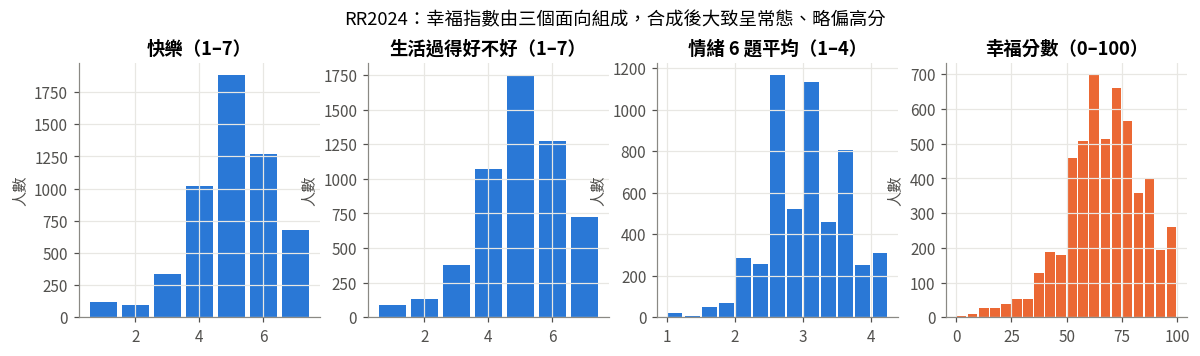

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
s = main[main.year == 2024]
axes[0].hist(s.happy.dropna(), bins=np.arange(0.5, 8), color=PALETTE["blue"], rwidth=0.85)
axes[0].set_title("快樂（1–7）")
axes[1].hist(s.good.dropna(), bins=np.arange(0.5, 8), color=PALETTE["blue"], rwidth=0.85)
axes[1].set_title("生活過得好不好（1–7）")
axes[2].hist(s.affect6.dropna(), bins=np.arange(1, 4.26, 0.25), color=PALETTE["blue"], rwidth=0.85)
axes[2].set_title("情緒 6 題平均（1–4）")
axes[3].hist(s.swb.dropna(), bins=np.arange(0, 101, 5), color=PALETTE["orange"], rwidth=0.85)
axes[3].set_title("幸福分數（0–100）")
for a in axes: a.set_ylabel("人數")
fig.suptitle("RR2024：幸福指數由三個面向組成，合成後大致呈常態、略偏高分", y=1.04)
savefig(fig, "fig01_swb_components")

In [14]:
main[["pid", "year", "imp_marriage", "imp_support"]].to_csv(DERIVED / "importance_subscales.csv", index=False)